The central limit theorem through convolutions (Victor Z and Ugochukwu Ikegwu, UW-Madison, 2024).
For independent $X_i\sim\mathcal{U}(4,6)$ with pdf $f$, the pdf of $X_1+X_2$ is $\phi=f*f$, of
$X_1+X_2+X_3$ is $f*(f*f)$, and so on. We convolve numerically on a grid of step `dx`
(`phi = np.convolve(phi, f) * dx`) and compare with the Gaussian that has the same mean and variance.

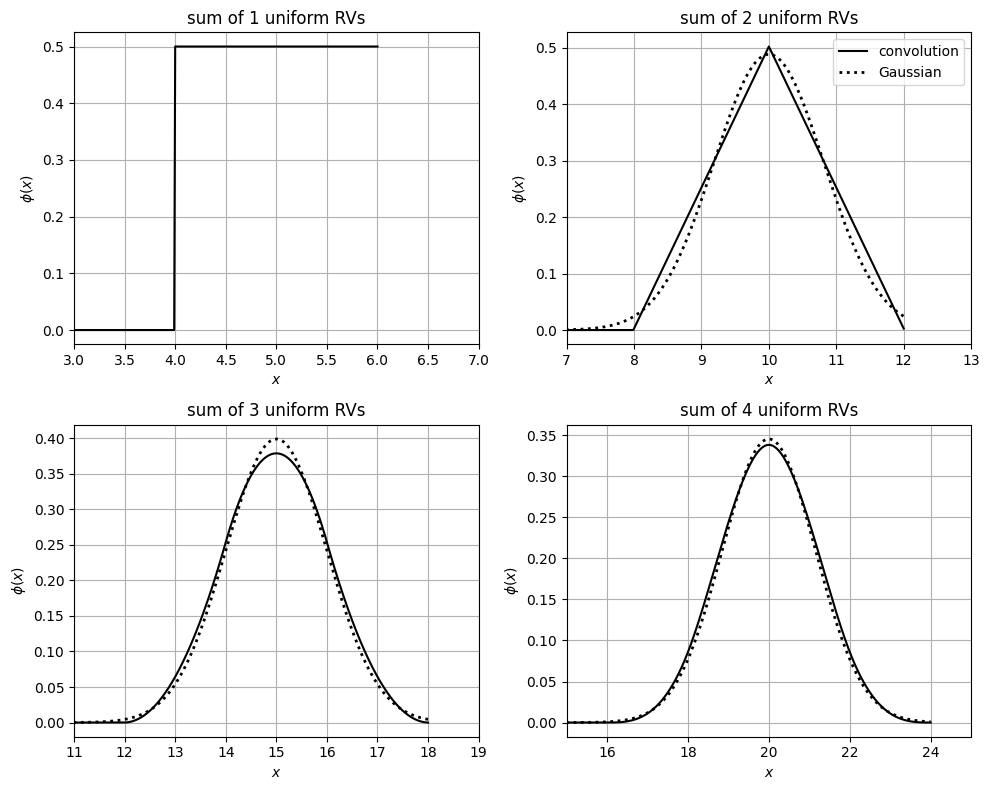

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import uniform, norm

dx = 0.01
x = np.arange(0, 6 + dx, dx)
f = uniform.pdf(x, loc=4, scale=2)

fig, axs = plt.subplots(2, 2, figsize=(10, 8))
phi = f.copy()
for k, ax in enumerate(axs.ravel(), start=1):
    if k > 1:
        phi = np.convolve(phi, f) * dx               # pdf of X_1 + ... + X_k
    xk = np.arange(len(phi)) * dx
    ax.plot(xk, phi, 'k', linewidth=1.5, label='convolution')
    if k > 1:
        ax.plot(xk, norm.pdf(xk, 5 * k, np.sqrt(k * 4 / 12)), 'k:', linewidth=2, label='Gaussian')
    ax.set_xlim(4 * k - 1, 6 * k + 1)
    ax.set_title(f'sum of {k} uniform RVs')
    ax.set_xlabel('$x$'); ax.set_ylabel(r'$\phi(x)$')
    ax.grid(True)
axs[0, 1].legend()
plt.tight_layout()
plt.show()